<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_class_practice/blob/main/Assignment_07_Brain_Tumor_Classification_using_CNN_architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Import Standard Libraries

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import VGG19, ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

## Path Setup and Data Loading (Lab Style)

In [ ]:
# Modify path as needed to match your Drive
dataset_dir = '/content/drive/MyDrive/Colab Notebooks/Assignment 6/Method 1/brain_tumor_dataset'
no_dir = os.path.join(dataset_dir, 'no')
yes_dir = os.path.join(dataset_dir, 'yes')

IMG_SIZE = 224 # Changed to 224 for VGG/ResNet compatibility
data = []
labels = []

print("Loading 'no' images (label 0)...")
for img_name in os.listdir(no_dir):
    try:
        img_path = os.path.join(no_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        data.append(img)
        labels.append(0)
    except Exception as e:
        pass

print("Loading 'yes' images (label 1)...")
for img_name in os.listdir(yes_dir):
    try:
        img_path = os.path.join(yes_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        data.append(img)
        labels.append(1)
    except Exception as e:
        pass

# Normalization and converting to Numpy arrays
X = np.array(data, dtype='float32') / 255.0
y = np.array(labels)

print(f"Total dataset shape: {X.shape}")
print(f"Total labels shape: {y.shape}")

Loading 'no' images (label 0)...
Loading 'yes' images (label 1)...
Total dataset shape: (253, 224, 224, 3)
Total labels shape: (253,)


## Train-Test Split (80% Train, 20% Test)

In [ ]:
# Splitting the data just like your previous lab
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Train samples: 202, Test samples: 51


## Model 1 - Custom VGG19

In [ ]:
def get_vgg19_model():
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

    # Freeze the base layers
    base_model.trainable = False

    x = Flatten()(base_model.output)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.4)(x)
    output_layer = Dense(1, activation='sigmoid')(x) # Binary Output (0 or 1)

    model = Model(inputs=base_model.input, outputs=output_layer)
    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

vgg19_clf = get_vgg19_model()
print("VGG19 Pipeline Ready.")

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG19 Pipeline Ready.


## Model 2 - Custom ResNet50

In [ ]:
def get_resnet50_model():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

    base_model.trainable = False

    x = GlobalAveragePooling2D()(base_model.output)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.4)(x)
    output_layer = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output_layer)
    model.compile(optimizer=Adam(learning_rate=0.0001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

resnet50_clf = get_resnet50_model()
print("ResNet50 Pipeline Ready.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 Pipeline Ready.


## Model Training

In [ ]:
EPOCHS = 15
BATCH_SIZE = 16

print("================ Training VGG19 ================")
vgg_history = vgg19_clf.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)

print("\n================ Training ResNet50 ================")
resnet_history = resnet50_clf.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)

================ Training VGG19 ================
Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 204s 16s/step - accuracy: 0.6634 - loss: 0.6467 - val_accuracy: 0.7843 - val_loss: 0.4613
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 195s 15s/step - accuracy: 0.8020 - loss: 0.4307 - val_accuracy: 0.8431 - val_loss: 0.3933
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 203s 15s/step - accuracy: 0.8267 - loss: 0.3411 - val_accuracy: 0.8039 - val_loss: 0.3683
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 200s 15s/step - accuracy: 0.8465 - loss: 0.3026 - val_accuracy: 0.8431 - val_loss: 0.3285
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 206s 15s/step - accuracy: 0.9010 - loss: 0.2917 - val_accuracy: 0.8235 - val_loss: 0.3470
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 197s 15s/step - accuracy: 0.8564 - loss: 0.3054 - val_accuracy: 0.8627 - val_loss: 0.3158
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 205s 15s/step - accuracy: 0.9257 - loss: 0.2190 - val_accuracy: 0.8824 - val_loss: 0.3165
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 194s 15s/step - a

## Accuracy and Loss Plots

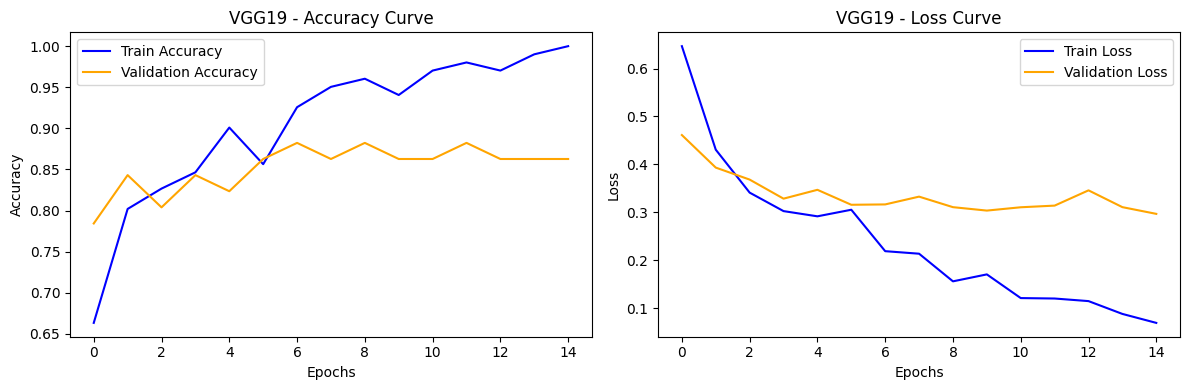

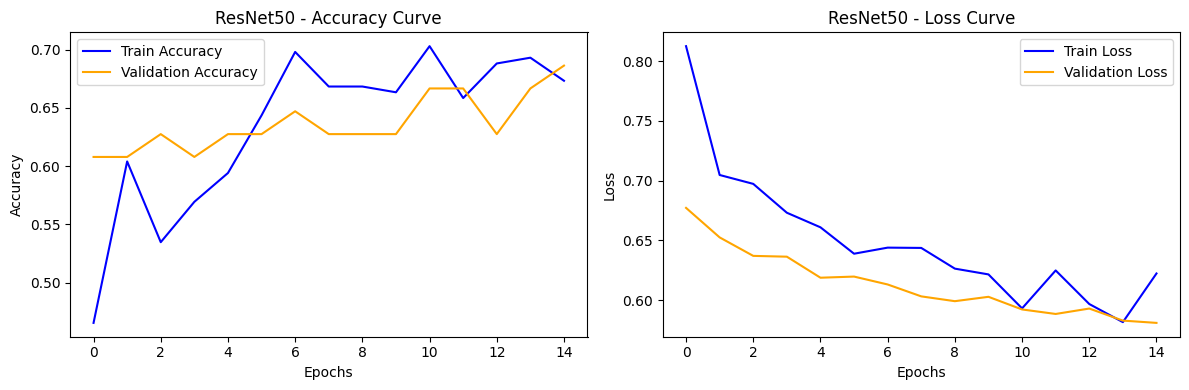

In [ ]:
def plot_performance(history, model_title):
    plt.figure(figsize=(12, 4))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
    plt.title(f'{model_title} - Accuracy Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title(f'{model_title} - Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Generate plots for both
plot_performance(vgg_history, "VGG19")
plot_performance(resnet_history, "ResNet50")

## Final Performance **Comparison**

Evaluating Models on Test Data...
VGG19 Test Accuracy: 86.27%
ResNet50 Test Accuracy: 68.63%


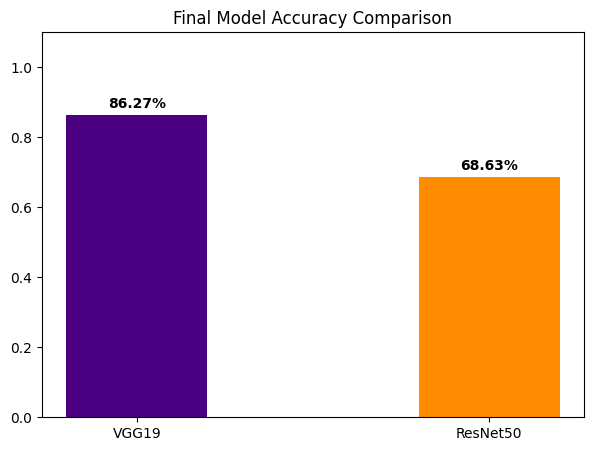

In [ ]:
print("Evaluating Models on Test Data...")
vgg_loss, vgg_test_acc = vgg19_clf.evaluate(X_test, y_test, verbose=0)
res_loss, res_test_acc = resnet50_clf.evaluate(X_test, y_test, verbose=0)

print(f"VGG19 Test Accuracy: {vgg_test_acc*100:.2f}%")
print(f"ResNet50 Test Accuracy: {res_test_acc*100:.2f}%")

# Bar Chart
plt.figure(figsize=(7, 5))
bars = plt.bar(['VGG19', 'ResNet50'], [vgg_test_acc, res_test_acc], color=['#4b0082', '#ff8c00'], width=0.4)
plt.title('Final Model Accuracy Comparison')
plt.ylim(0, 1.1)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.02,
             f"{height*100:.2f}%", ha='center', fontweight='bold')
plt.show()